# 04_06 – Подготовка независимой проверки трех пар

Проверка исходных измерений пока не завершена. Публичный архив OpenSky не содержит нужные интервалы: для 02.01.2019 и 30.04.2019 целевых снимков нет; для 12.08.2019 доступны только часы 00–12 UTC, а событие EDDF относится к 16–17 UTC. Результат проверки каталога сохранен отдельно.

Из локального validation_sample.zip извлекаем точки трех ранних сегментов. Это дополнительные материалы исходного исследования, не независимые измерения другой системы или заново полученная траектория OpenSky. Идентификация в HTML основана на flight_id; ICAO24 в извлеченных точках отсутствует. Высоту сохраняем в исходных значениях без предположения об единице.

Подготавливаем три ограниченных SQL-запроса к историческому Trino. [Официальная документация](https://openskynetwork.github.io/opensky-api/trino.html) требует одобренного доступа и ограничения по часовым разделам.

In [1]:
# Находим проект и извлекаем уже имеющиеся материалы без повторной загрузки архива
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]
          if (p/'europe/data/source/osn23_landings_merged.parquet.gzip').exists())
sys.path.insert(0,str(ROOT/'europe/scripts'))
import prepare_independent_checks as analysis

# Сохраняем происхождение точек и отдельный статус независимой проверки
cases=analysis.main()
display(cases)

{
  "input_sha256": "ddf11438bab44137242ffcf4da928418e116efd46defce58dc8a388b67942b6d",
  "input_unchanged": true,
  "rows_changed": 0,
  "rows_deleted": 0,
  "archive": "archive\\2019_experiment\\data\\raw\\validation_sample.zip",
  "archive_sha256": "2ba9025c9bb5d1e1cab6e01bb442721650a10d4d3488cecbc14b2d974e48d5cb",
  "cases": [
    {
      "pair_id": 42,
      "airport": "LFPG",
      "icao24": "3c65c1",
      "early_flight_id": "DLH77X_127043",
      "late_flight_id": "DLH77X_127044",
      "published_points": 74,
      "first_point": "2019-04-30 06:27:05+00:00",
      "last_point": "2019-04-30 07:02:28+00:00",
      "minimum_source_altitude": 550.0,
      "last_source_altitude": 3700.0,
      "altitude_unit": "not established from HTML; retained as source values",
      "archive_member": "validation_sample/LFPG_09L.html",
      "member_sha256": "881533ca830b76f13de9f9d0a670d013745fa507bac0b830b40674e5be57d51b",
      "source_independent_of_labeling_pipeline": false,
      "indepen

,pair_id,airport,icao24,early_flight_id,late_flight_id,published_points,first_point,last_point,minimum_source_altitude,last_source_altitude,altitude_unit,archive_member,member_sha256,source_independent_of_labeling_pipeline,independent_state_vectors_downloaded,query_start,query_end,status
0,42,LFPG,3c65c1,DLH77X_127043,DLH77X_127044,74,2019-04-30 06:27:05+00:00,2019-04-30 07:02:28+00:00,550.0,3700.0,not established from HTML; retained as source ...,validation_sample/LFPG_09L.html,881533ca830b76f13de9f9d0a670d013745fa507bac0b8...,False,False,2019-04-30 06:06:28+00:00,2019-04-30 07:40:13+00:00,published_points_extracted; independent_check_...
1,46,EDDM,3c6605,DLH2527_74481,DLH2527_74482,243,2019-01-02 13:29:28+00:00,2019-01-02 14:09:47+00:00,2125.0,6475.0,not established from HTML; retained as source ...,validation_sample/EDDM_26R.html,54318c725dde3f9a3c1e02d1b02d82109ffd5f78a620d7...,False,False,2019-01-02 13:14:33+00:00,2019-01-02 14:46:03+00:00,published_points_extracted; independent_check_...
2,131,EDDF,506c2f,ADR118_209541,ADR118_209542,58,2019-08-12 16:33:07+00:00,2019-08-12 16:59:40+00:00,800.0,4850.0,not established from HTML; retained as source ...,validation_sample/EDDF_25R.html,aecb6a97008774b55f916c53df0b64a604fcad3e150ff0...,False,False,2019-08-12 16:13:33+00:00,2019-08-12 17:40:24+00:00,published_points_extracted; independent_check_...


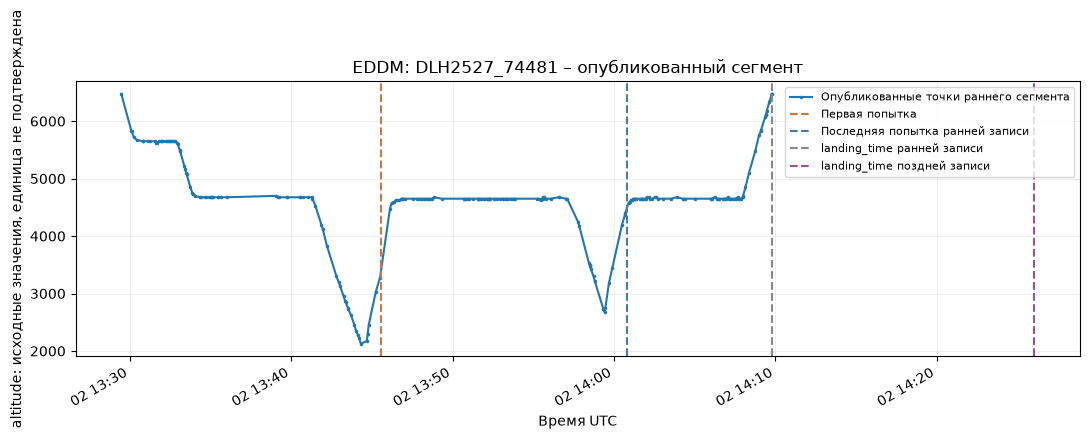

In [2]:
# Сравниваем опубликованные точки EDDM с временами обеих записей
analysis.plot_case('EDDM')
plt.show()

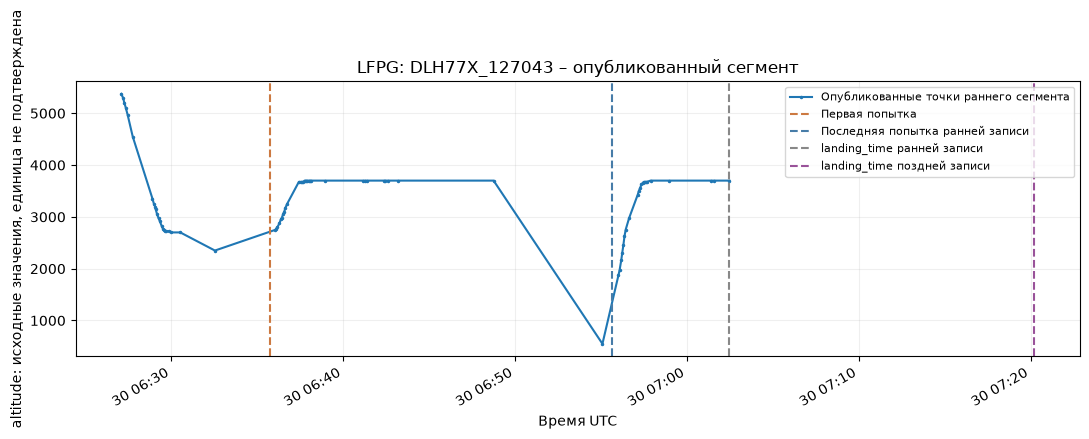

In [3]:
# Сравниваем опубликованные точки LFPG с временами обеих записей
analysis.plot_case('LFPG')
plt.show()

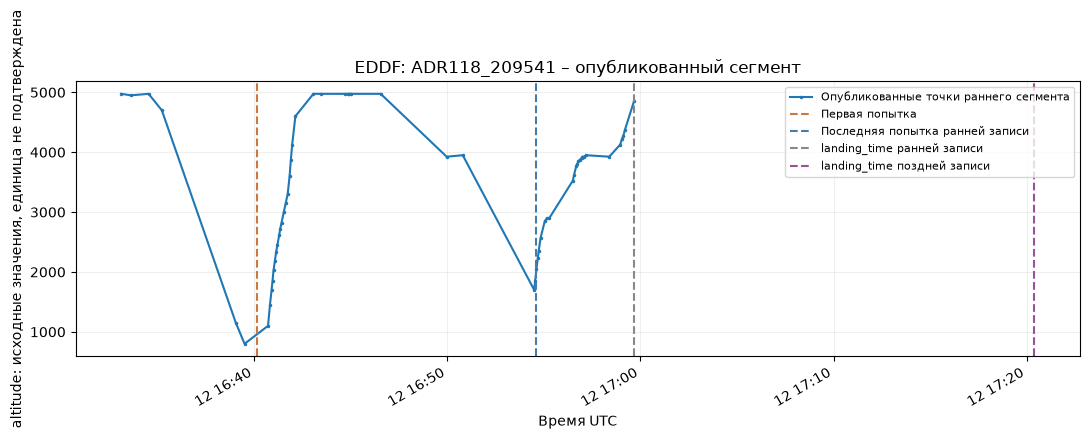

In [4]:
# Сравниваем опубликованные точки EDDF с временами обеих записей
analysis.plot_case('EDDF')
plt.show()

## Вывод и дальнейшие действия

Во всех трех опубликованных ранних сегментах последняя точка имеет ненулевое значение altitude и совпадает с landing_time ранней записи. Это ставит под сомнение интерпретацию landing_time как времени касания ВПП, но не удостоверяет истинный момент посадки. Высота не приравнивается к высоте над аэродромом, наземная фаза не восстановлена.

Для независимой проверки необходимо получить state vectors по подготовленным запросам, проверить свежесть позиции и контакта, пробелы наблюдения, снижение/набор, onground и движение после предполагаемой посадки. Отдельно проверить вход C40. Отсутствие наблюдения не доказывает отсутствие события.

До получения независимых данных обе записи каждой пары сохраняются. [Статус и источники](../../reports/analytical_sample/04_06_review.md).